In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/raw/train.csv", parse_dates=["date"])

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    913000 non-null  datetime64[us]
 1   store   913000 non-null  int64         
 2   item    913000 non-null  int64         
 3   sales   913000 non-null  int64         
dtypes: datetime64[us](1), int64(3)
memory usage: 27.9 MB


In [3]:
df.describe()

,date,store,item,sales
count,913000,913000.000000,913000.000000,913000.000000
mean,2015-07-02 12:00:00,5.500000,25.500000,52.250287
min,2013-01-01 00:00:00,1.000000,1.000000,0.000000
25%,2014-04-02 00:00:00,3.000000,13.000000,30.000000
50%,2015-07-02 12:00:00,5.500000,25.500000,47.000000
75%,2016-10-01 00:00:00,8.000000,38.000000,70.000000
max,2017-12-31 00:00:00,10.000000,50.000000,231.000000
std,NaN,2.872283,14.430878,28.801144


In [4]:
df.isna().sum()

date     0
store    0
item     0
sales    0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
print(df["date"].min(), df["date"].max())

2013-01-01 00:00:00 2017-12-31 00:00:00


In [7]:
print(df["date"].nunique() * df["store"].nunique() * df["item"].nunique(), len(df))

913000 913000


In [8]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates 
import seaborn as sns

<Axes: title={'center': 'Total Penjualan Bulanan'}, xlabel='date'>

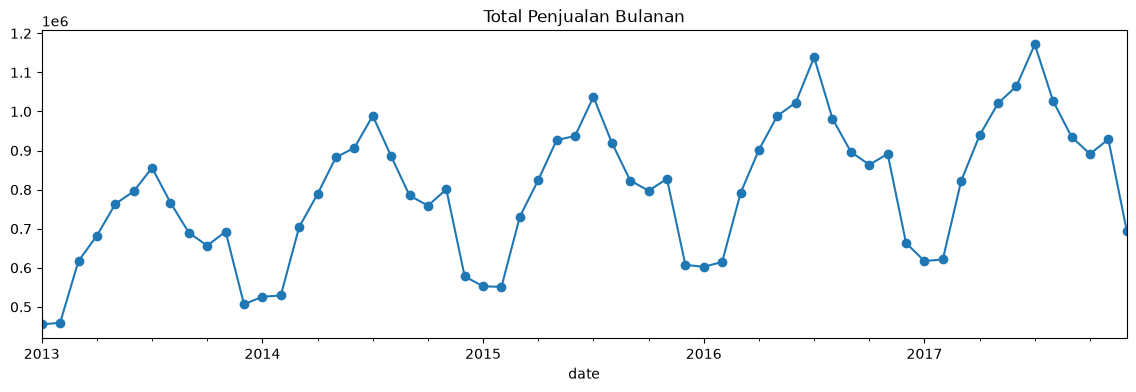

In [9]:
# Trend total penjualan bulanan
monthly = df.set_index("date")["sales"].resample("ME").sum()
monthly.plot(figsize=(14, 4), title="Total Penjualan Bulanan", marker="o")

<Axes: xlabel='dayofweek', ylabel='sales'>

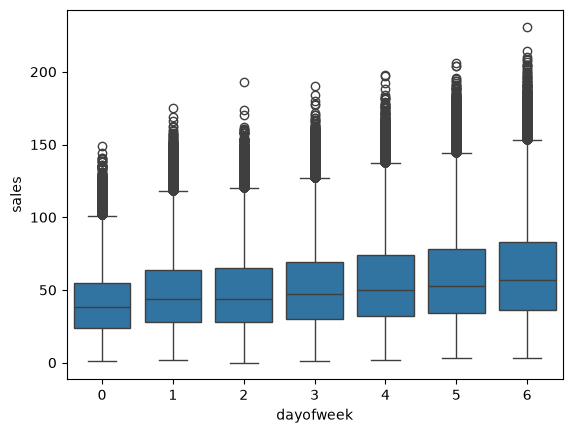

In [10]:
# Pola hari dalam seminggu
df["dayofweek"] = df["date"].dt.dayofweek
sns.boxplot(data=df, x="dayofweek", y="sales")

<Axes: ylabel='store'>

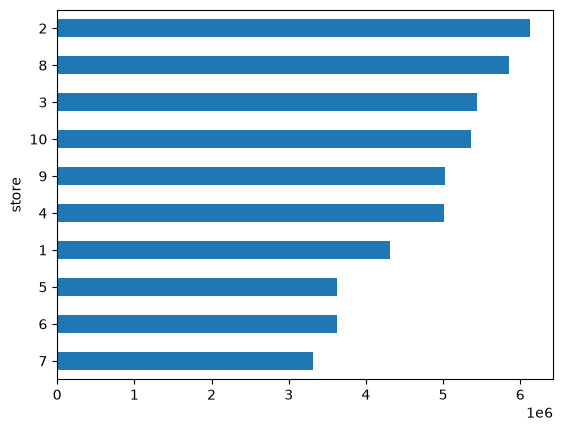

In [11]:
# Perbandingan antar toko
df.groupby("store")["sales"].sum().sort_values().plot.barh()

<Axes: xlabel='store', ylabel='store'>

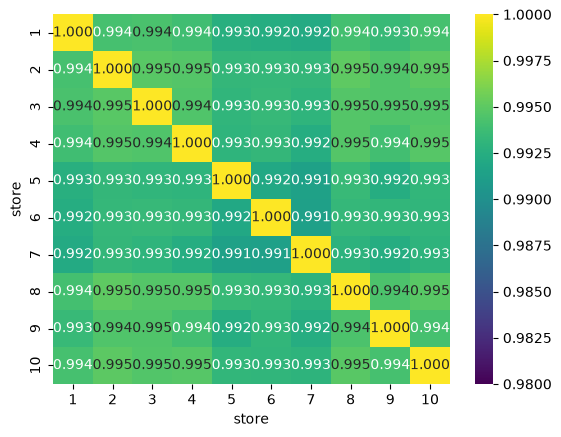

In [12]:
# Korelasi antar toko
pivot = df.pivot_table(index="date", columns="store", values="sales", aggfunc="sum")
sns.heatmap(pivot.corr(), annot=True, fmt=".3f", vmin=0.98, vmax=1.0, cmap="viridis")

In [13]:
# Calendar features
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["dayofweek"] = df["date"].dt.dayofweek
df["weekofyear"] = df["date"].dt.isocalendar().week.astype(int)

In [14]:
df = df.sort_values(["store", "item", "date"]).reset_index(drop=True)
g = df.groupby(["store", "item"])["sales"]

for lag in [91, 98, 182, 364]:
    df[f"lag_{lag}"] = g.shift(lag)

df["roll_mean_91_28"] = g.transform(lambda s: s.shift(91).rolling(28).mean())

* Train: untuk melatih model
* Validation: untuk evaluasi saat refinement
* Test: disimpan, dipakai sekali di akhir sebagai penilaian jujur

In [15]:
cutoff = "2017-10-03"
train = df[df["date"] < cutoff].dropna()

# Valid = 90 hari terakhir dari data train
valid = df[df["date"] >= cutoff].dropna()

In [16]:
# Metrik dan baseline
def smape(y_true, y_pred):
    denom = np.abs(y_true) + np.abs(y_pred)
    return 100 * np.mean(np.where(denom == 0, 0, 2 * np.abs(y_pred - y_true) / denom))

# Baseline 1: seasonal naive (nilai di hari yang sama tahun lalu)
base_naive = valid["lag_364"]

# Baseline 2: rata-rata per store, item, dan hari dalam seminggu dari data train
dow_mean = train.groupby(["store", "item", "dayofweek"])["sales"].mean().rename("dow_mean")
valid = valid.join(dow_mean, on=["store", "item", "dayofweek"])

print("SMAPE seasonal naive :", smape(valid["sales"], base_naive))
print("SMAPE dow mean       :", smape(valid["sales"], valid["dow_mean"]))

SMAPE seasonal naive : 17.865485634917317
SMAPE dow mean       : 17.296058974888666


In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from xgboost import XGBRegressor

In [18]:
# Linear Regression
features = ["store", "item", "year", "month", "day", "dayofweek", "weekofyear", "lag_91", "lag_98", "lag_182", "lag_364", "roll_mean_91_28"]

X_train, y_train = train[features], train["sales"]
X_valid, y_valid = valid[features], valid["sales"]

lr = LinearRegression().fit(X_train, y_train)
pred_lr = lr.predict(X_valid)

In [19]:
# XGBoost
xgb = XGBRegressor(n_estimators=500, learning_rate=0.05,
                   max_depth=6, subsample=0.8, colsample_bytree=0.8,
                   random_state=42)

xgb.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
pred_xgb = xgb.predict(X_valid)

In [20]:
for name, predict in [("Linear Regression", pred_lr), ("XGBoost", pred_xgb)]:
    print(name, "| MAE:", mean_absolute_error(y_valid, predict),
          "| SMAPE:", smape(y_valid, predict),
          "| R2:", r2_score(y_valid, predict))

Linear Regression | MAE: 7.857922100554096 | SMAPE: 16.16725773311737 | R2: 0.8705813318799678
XGBoost | MAE: 5.939309597015381 | SMAPE: 12.504049055163577 | R2: 0.9265064001083374


In [21]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import make_scorer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

In [22]:
# Time Series Split Cross Validation
train = train.sort_values("date").reset_index(drop=True)
X_train, y_train = train[features], train["sales"]

tscv = TimeSeriesSplit(n_splits=3)
smape_scorer = make_scorer(smape, greater_is_better=False)

In [23]:
# Pipeline dan GridSearchCV untuk Ridge

pipe = Pipeline([("scaler", StandardScaler()),
                ("ridge", Ridge())])

param_ridge = {"ridge__alpha":[0.01, 0.1, 1, 10, 100]}

grid_ridge = GridSearchCV(pipe, param_ridge, cv=tscv,
                          scoring=smape_scorer, n_jobs=-1)
grid_ridge.fit(X_train, y_train)

print("Alpha terbaik :", grid_ridge.best_params_)
print("SMAPE CV       :", -grid_ridge.best_score_)

pred_ridge = grid_ridge.predict(X_valid)
print("SMAPE valid    :", smape(y_valid, pred_ridge))

Alpha terbaik : {'ridge__alpha': 100}
SMAPE CV       : 36.407886833816505
SMAPE valid    : 16.166069793997686


In [24]:
# GridSearchCV untuk XGBoost
# Tuning menggunakan data 2015 ke atas

train_tune = train[train["date"] >= "2015-01-01"]
X_tune, y_tune = train_tune[features], train_tune["sales"]

param_xgb = {
    "max_depth":[4,6,8],
    "learning_rate":[0.03,0.1],
    "n_estimators":[300, 600],
}

grid_xgb = GridSearchCV(
    XGBRegressor(subsample=0.8, colsample_bytree=0.8,
                 tree_method="hist", random_state=42),
    param_xgb, cv=tscv, scoring=smape_scorer, n_jobs=1, verbose=1)

grid_xgb.fit(X_tune, y_tune)

print("Parameter terbaik :", grid_xgb.best_params_)
print("SMAPE Cross-val   :", -grid_xgb.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Parameter terbaik : {'learning_rate': 0.03, 'max_depth': 8, 'n_estimators': 600}
SMAPE Cross-val   : 13.586581078770344


In [25]:
best_xgb = XGBRegressor(**grid_xgb.best_params_, subsample=0.8, colsample_bytree=0.8, tree_method="hist", random_state=42)

best_xgb.fit(X_train, y_train)
pred_best = best_xgb.predict(X_valid)

In [26]:
# Bandingkan semua model dalam satu tabel
results = pd.DataFrame({
    "Model": ["Seasonal naive", "DOW mean", "Linear Regression",
              "Ridge (tuned)", "XGBoost (tuned)"],
    "SMAPE": [
        smape(y_valid, valid["lag_364"]),
        smape(y_valid, valid["dow_mean"]),
        smape(y_valid, pred_lr),
        smape(y_valid, pred_ridge),
        smape(y_valid, pred_best),
    ],
    "MAE": [
        mean_absolute_error(y_valid, valid["lag_364"]),
        mean_absolute_error(y_valid, valid["dow_mean"]),
        mean_absolute_error(y_valid, pred_lr),
        mean_absolute_error(y_valid, pred_ridge),
        mean_absolute_error(y_valid, pred_best),
    ]
}).sort_values("SMAPE")

results

,Model,SMAPE,MAE
4,XGBoost (tuned),12.457008,5.919904
3,Ridge (tuned),16.166070,7.857757
2,Linear Regression,16.167258,7.857922
1,DOW mean,17.296059,8.758047
0,Seasonal naive,17.865486,8.350489


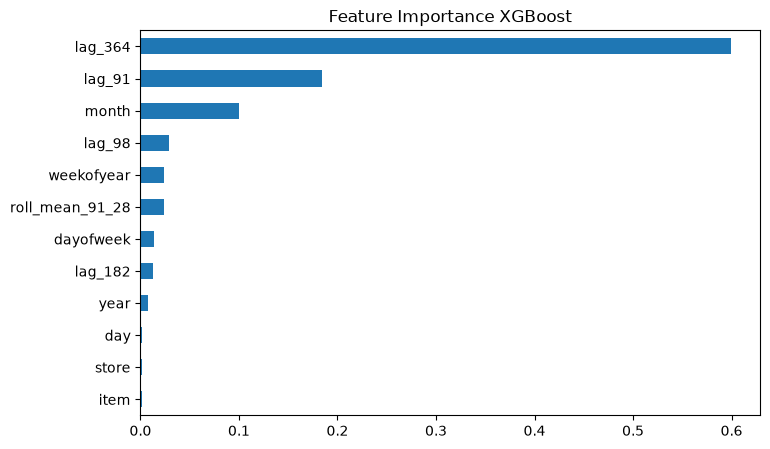

In [27]:
# Visualisasi Feature Importance
fig, ax = plt.subplots(figsize=(8, 5))
pd.Series(best_xgb.feature_importances_, index=features).sort_values().plot.barh(ax=ax)
ax.set_title("Feature Importance XGBoost")
fig.savefig("../reports/figures/feature_importances.png",
            dpi=150, bbox_inches="tight")

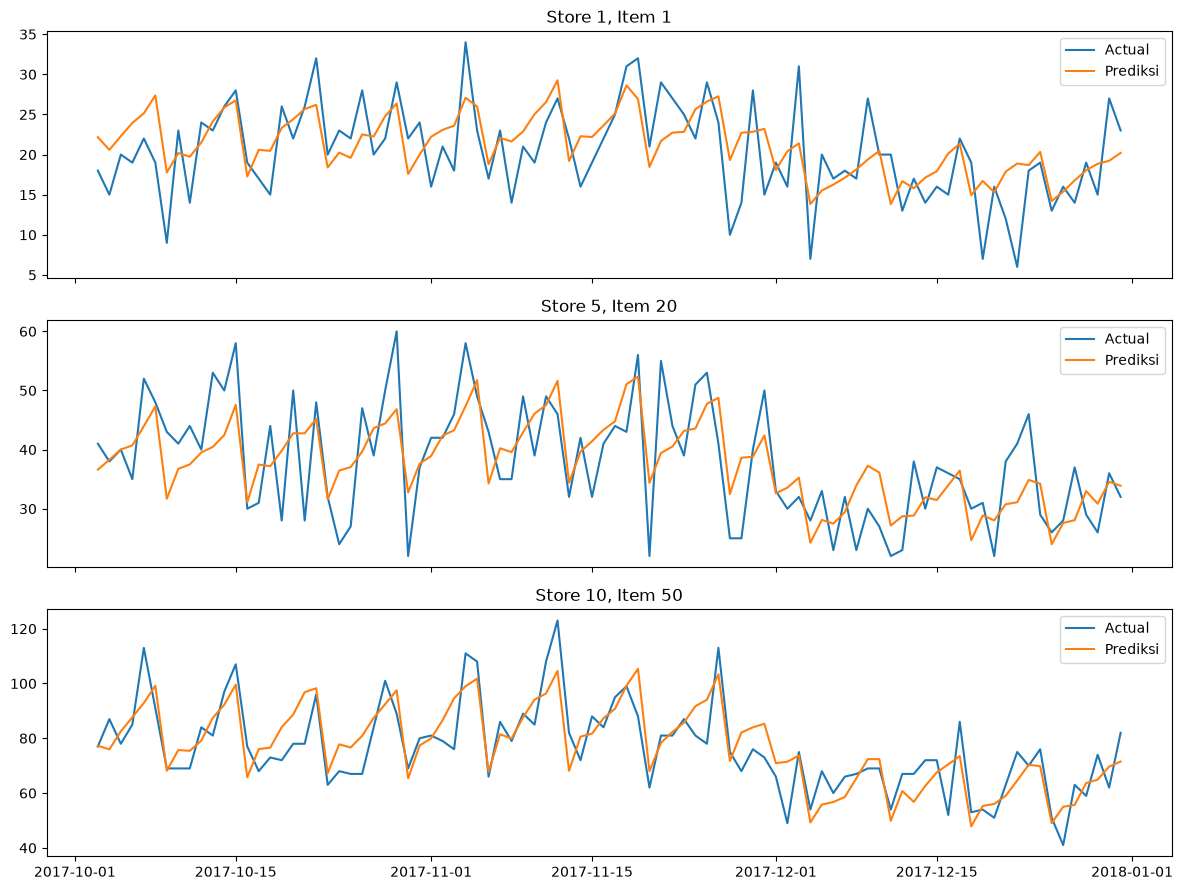

In [28]:
# Plot actual vs prediksi
valid = valid.assign(pred=pred_best)
combos = [(1, 1), (5, 20), (10, 50)] # (store, item)

fig, axes = plt.subplots(len(combos), 1, figsize=(12, 9), sharex=True)
for ax, (s, i) in zip(axes, combos):
    sub = valid[(valid["store"] == s) & (valid["item"] == i)].sort_values("date")
    ax.plot(sub["date"], sub["sales"], label="Actual")
    ax.plot(sub["date"], sub["pred"], label="Prediksi")
    ax.set_title(f"Store {s}, Item {i}")
    ax.legend()

fig.tight_layout()
fig.savefig("../reports/figures/actual_vs_pred.png", dpi=150)

In [29]:
# Prediksi 90 hari ke depan

def build_features(frame):
    frame = frame.sort_values(["store", "item",
                               "date"]).reset_index(drop=True)
    frame["year"] = frame["date"].dt.year
    frame["month"] = frame["date"].dt.month
    frame["day"] = frame["date"].dt.day
    frame["dayofweek"] = frame["date"].dt.dayofweek
    frame["weekofyear"] = frame["date"].dt.isocalendar().week.astype(int)

    g = frame.groupby(["store", "item"])["sales"]

    for lag in [91, 98, 182, 364]:
        frame[f"lag_{lag}"] = g.shift(lag)
    frame["roll_mean_91_28"] = g.transform(lambda s: s.shift(91)
        .rolling(28).mean())

    return frame

In [30]:
raw = pd.read_csv("../data/raw/train.csv", parse_dates=["date"])
test = pd.read_csv("../data/raw/test.csv", parse_dates=["date"])

full = build_features(pd.concat([raw, test], ignore_index=True))
labeled = full[full["id"].isna()].dropna(subset=features)
to_predict = full[full["id"].notna()]

final_model = XGBRegressor(**grid_xgb.best_params_, subsample=0.8,
                           colsample_bytree=0.8, tree_method="hist",
                           random_state=42)
final_model.fit(labeled[features], labeled["sales"])

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [31]:
preds = final_model.predict(to_predict[features]).clip(min=0).round().astype(int)

submission = pd.DataFrame({"id": to_predict["id"].astype(int),
                           "sales": preds})

In [32]:
submission.sort_values("id").to_csv("../reports/submission.csv", index=False)

In [37]:
print(submission.shape)
print(submission.head())
print(submission["sales"].describe())
print(submission["id"].is_unique)

(45000, 2)
      id  sales
1826   0     13
1827   1     15
1828   2     15
1829   3     15
1830   4     17
count    45000.000000
mean        47.756711
std         23.743856
min          8.000000
25%         28.000000
50%         44.000000
75%         63.000000
max        155.000000
Name: sales, dtype: float64
True


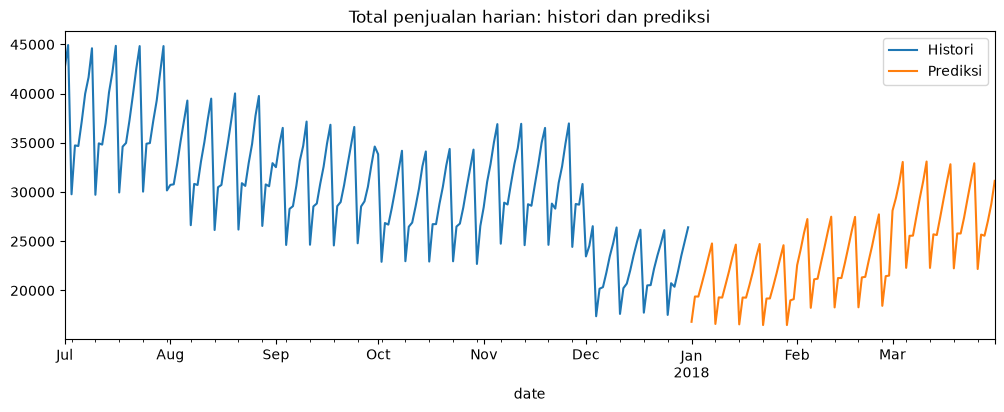

In [38]:
# Total penjualan harian: histori vs prediksi
hist = raw.groupby("date")["sales"].sum()
pred_harian = (to_predict.assign(sales=preds)
               .groupby("date")["sales"].sum())

fig, ax = plt.subplots(figsize=(12, 4))
hist["2017-07-01":].plot(ax=ax, label="Histori")
pred_harian.plot(ax=ax, label="Prediksi")
ax.set_title("Total penjualan harian: histori dan prediksi")
ax.legend()
plt.show()